In [52]:
import librosa
import librosa.display

from core.musicProcessing import MusicProcessingProvider as mp
from core.alg import Alg
from core.alg_bins import AlgBins
from core.alg_binary import AlgBinary
from core.individual import Individual
from core.individual_bins import Individual_bins
from core.individual_binary import Individual_binary

from time import time
import matplotlib.pyplot as plt
import numpy as np

In [53]:
# mp params
path = "/home/bordduk69/Nextcloud/Music/Mario/Main 2D/New Super Mario Bros. Wii/New Super Mario Bros. Wii Music - Forest.mp3"
duration = None
nfft = 2048
win_length = 2048
hop_length = 1024
window_type = "hann"

music_processor = mp(path, duration, nfft, hop_length, win_length, window_type)

In [54]:
num_generations = 400
population_size = 400
random_seed = 42
sharing_radius = 0.9
mutation_probability = 0.15
crossover_probability = 0.7
population_initialization_method = "random" # "random" or "elite"
selection_method = "tournament" # "tournament" or "roulette"
crossover_method = "two_point" # "single_point" , "two_point" or "rrc"
sim_metric = "fenotype" # "jaccard", "cosine", "cosine_blurred" or "fenotype"
Individual_bin_count = 20

alg = AlgBins(mp=music_processor, random_seed=random_seed, num_generations=num_generations, population_size=population_size, individual_bin_count=Individual_bin_count, mutation_probability=mutation_probability, crossover_probability=crossover_probability, crossover_method=crossover_method, selection_method=selection_method, sim_metric=sim_metric, sharing_radius=sharing_radius, population_initialization_method=population_initialization_method)

In [55]:
alg.run()

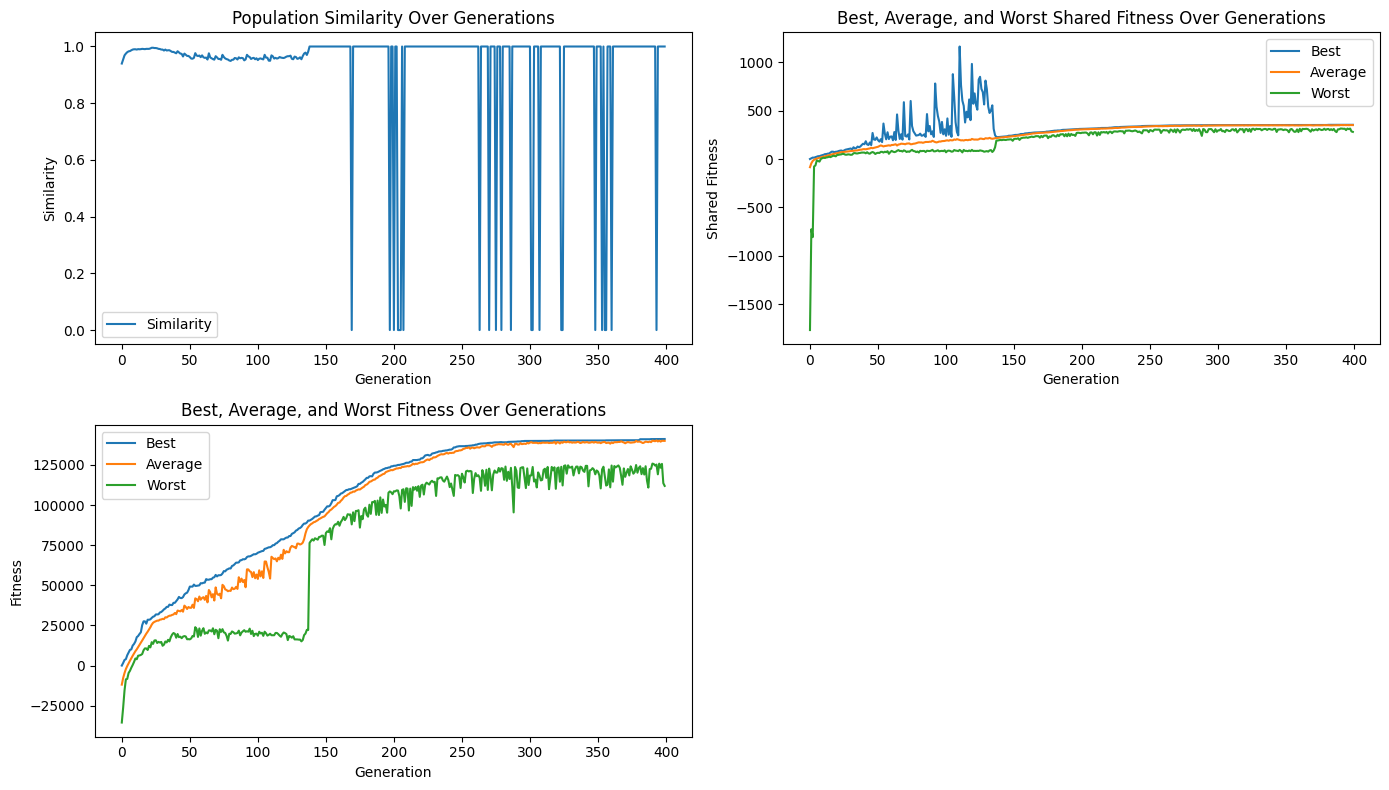

In [56]:
# plot stored metrics
plt.figure(figsize=(14, 8))
plt.subplot(2, 2, 1)
plt.plot(alg.avg_similarity, label="Similarity")
plt.xlabel("Generation")
plt.ylabel("Similarity")
plt.title("Population Similarity Over Generations")
plt.legend()
plt.subplot(2, 2, 2)
plt.plot(alg.best_shared_fitness, label="Best")
plt.plot(alg.avg_shared_fitness, label="Average")
plt.plot(alg.worst_shared_fitness, label="Worst")
plt.xlabel("Generation")
plt.ylabel("Shared Fitness")
plt.title("Best, Average, and Worst Shared Fitness Over Generations")
plt.legend()
plt.subplot(2, 2, 3)
plt.plot(alg.best_fitness, label="Best")
plt.plot(alg.avg_fitness, label="Average")
plt.plot(alg.worst_fitness, label="Worst")
plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.title("Best, Average, and Worst Fitness Over Generations")
plt.legend()
plt.tight_layout()
plt.show()

In [57]:
results = sorted(alg.population, key=lambda ind: ind.shared_fitness, reverse=True)[:5]
for i, ind in enumerate(results):
    print(f"Best individual from niche {i+1}: Fitness = {ind.fitness:.4f} Genome = {ind.genome}")

Best individual from niche 1: Fitness = 141128.4062 Genome = [(302, 61), (491, 50), (586, 49), (679, 50), (866, 50), (965, 40), (1147, 51), (1619, 47), (1807, 47), (2836, 49), (2929, 50), (3489, 53), (3681, 48), (3867, 49), (3960, 50), (4244, 47), (4618, 48), (4802, 52), (5647, 51), (5928, 62)]
Best individual from niche 2: Fitness = 141128.4062 Genome = [(302, 61), (491, 50), (586, 49), (679, 50), (866, 50), (965, 40), (1147, 51), (1619, 47), (1807, 47), (2836, 49), (2929, 50), (3489, 53), (3681, 48), (3867, 49), (3960, 50), (4244, 47), (4618, 48), (4802, 52), (5647, 51), (5928, 62)]
Best individual from niche 3: Fitness = 141128.4062 Genome = [(302, 61), (491, 50), (586, 49), (679, 50), (866, 50), (965, 40), (1147, 51), (1619, 47), (1807, 47), (2836, 49), (2929, 50), (3489, 53), (3681, 48), (3867, 49), (3960, 50), (4244, 47), (4618, 48), (4802, 52), (5647, 51), (5928, 62)]
Best individual from niche 4: Fitness = 141128.4062 Genome = [(302, 61), (491, 50), (586, 49), (679, 50), (866, 

/tmp/ipykernel_777709/2340505142.py:19: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.axvspan(start, start + length, color=color, alpha=0.5, linewidth=0.8, edgecolor=color)


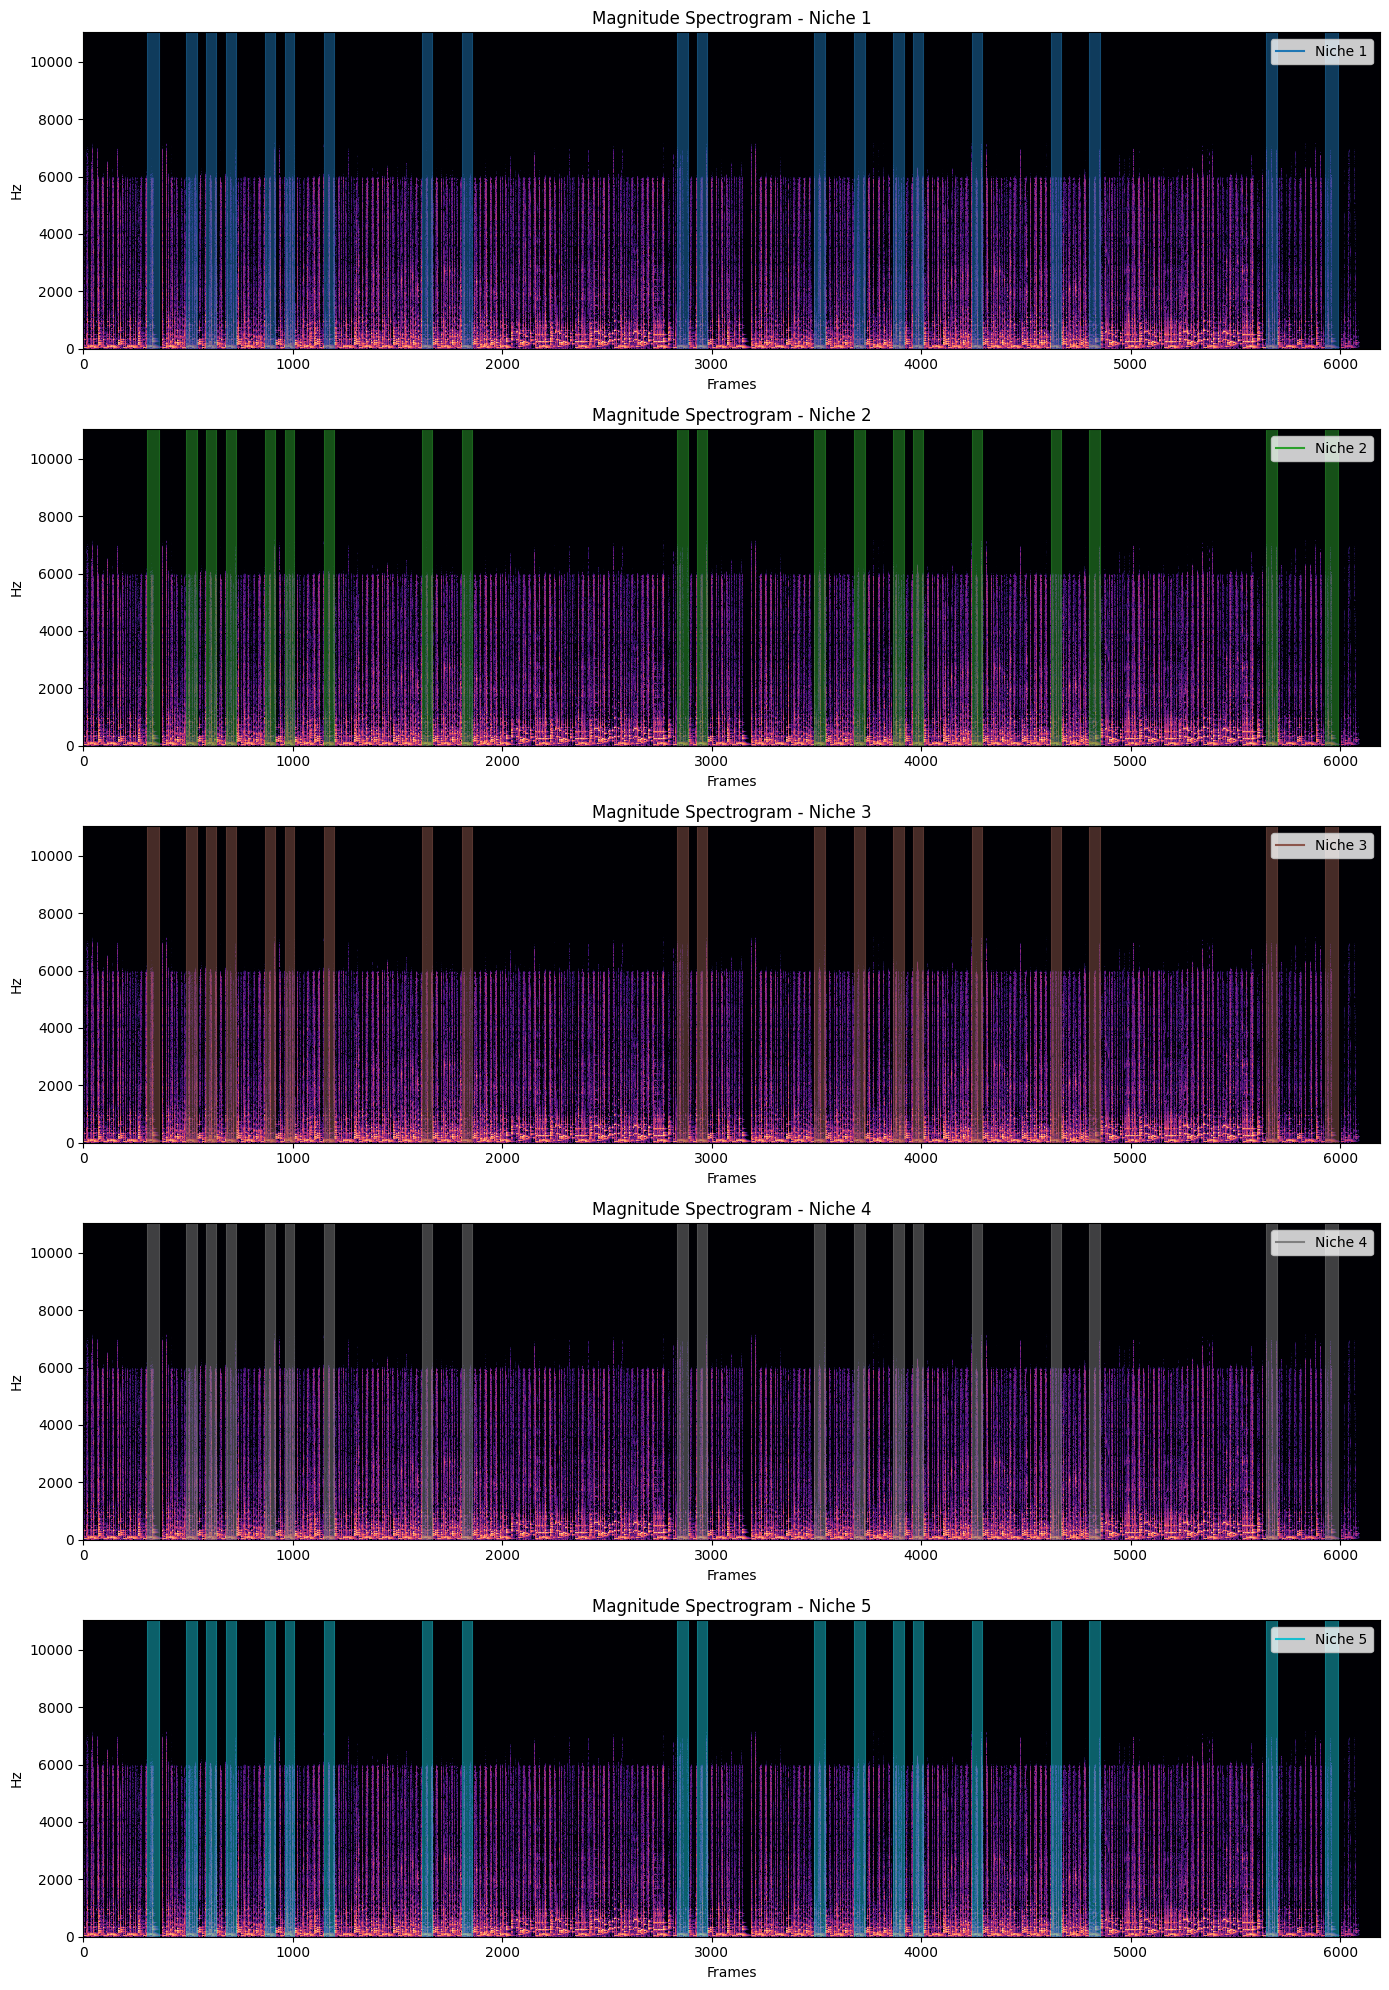

In [58]:
S_db = librosa.amplitude_to_db(music_processor.magnitude, ref=np.max)
plot_count = min(10, len(results))
colors = plt.cm.tab10(np.linspace(0, 1, max(1, plot_count)))

cols = 1
rows = int(np.ceil(plot_count / cols))
fig, axes = plt.subplots(rows, cols, figsize=(14, 4 * rows), squeeze=False)

for i, ind in enumerate(results[:plot_count]):
    ax = axes[i // cols][i % cols]
    img = librosa.display.specshow(S_db, x_axis="frames", y_axis="linear", cmap="magma", ax=ax)
    ax.set_title(f"Magnitude Spectrogram - Niche {i+1}")

    color = colors[i % len(colors)]
    for start, length in ind.genome:
        if length < 0:
            ax.axvspan(start + length, start, color=color, alpha=0.5, linewidth=0.8, edgecolor=color)
        else:
            ax.axvspan(start, start + length, color=color, alpha=0.5, linewidth=0.8, edgecolor=color)
    ax.plot([], [], color=color, label=f"Niche {i+1}")
    ax.legend(loc="upper right", frameon=True)

# hide unused axes if results < grid size
for j in range(plot_count, rows * cols):
    axes[j // cols][j % cols].axis("off")

plt.tight_layout()
plt.show()